<a href="https://colab.research.google.com/github/ShikharVeer10/TokenCompression/blob/main/Token_Compression_Capstone_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CAPSTONE PROJECT: End-to-End Budget-Optimized Token Compression Engine for Long-Context LLMs
### Final Year B.Tech in Computer Science and Engineering (AI & ML) | VIT-AP University
---
- **Domain:** Natural Language Processing, Deep Learning Infrastructure, Efficient Inference
- **Core Problem:** The KV-Cache Memory Bottleneck ($O(N)$ VRAM) & Quadratic Attention Complexity ($O(N^2)$ Latency)
- **Proposed Architecture:** Dual-Stage Optimization Middleware:
  1. **Pre-Inference Layer:** Information-Theoretic Prompt Distillation (LLMLingua-2 Token Classifier)
  2. **In-Inference Layer:** Heavy-Hitter Attention-Guided Dynamic KV-Cache Eviction (SnapKV / H2O)
- **Target Hardware:** Single Consumer/Cloud Free-Tier GPU (Nvidia Tesla T4 - 15GB VRAM)
- **Base Foundation LLM:** `Qwen/Qwen2.5-7B-Instruct` (Quantized via BitsAndBytes 4-bit NF4)


## Mathematical Formulation & Theoretical Framework

### 1. Pre-Inference Information Distillation (LLMLingua-2)
Given an input prompt $\mathcal{P} = (x_1, x_2, \dots, x_N)$ of $N$ tokens, the pre-inference classifier computes the conditional surprisal (information density) $I(x_i)$:
$$I(x_i) = -\log P_{	heta_{	ext{compressor}}}(x_i \mid x_{<i})$$
Tokens with low information content (filler words, boilerplate syntax, redundant conversational phrasing) are pruned to form a compressed prompt $\mathcal{P}'$ of length $M \le lpha N$ (where $lpha \in [0.3, 0.6]$).

### 2. In-Inference Attention-Guided KV-Cache Eviction (SnapKV)
For an attention head with keys $\mathbf{K} \in \mathbb{R}^{B 	imes L 	imes D}$ and values $\mathbf{V} \in \mathbb{R}^{B 	imes L 	imes D}$, full caching scales linearly. SnapKV observes the attention weight matrix $\mathbf{A} \in \mathbb{R}^{W 	imes L}$ emitted by the trailing observation window queries $W$:
$$\mathbf{S}_j = rac{1}{|W|} \sum_{q \in W} \mathbf{A}_{q, j}, \quad j \in [S, L - W]$$
Applying 1D average pooling clustering with kernel size $k$:
$$\mathbf{	ilde{S}} = 	ext{AvgPool1D}(\mathbf{S}, 	ext{kernel}=k, 	ext{stride}=1)$$
We retain:
1. **Attention Sinks ($S$):** The first $S=16$ tokens to prevent attention collapse.
2. **Heavy-Hitters ($H$):** The top-$k$ tokens scoring highest in $\mathbf{	ilde{S}}$.
3. **Observation Window ($W$):** The most recent $W=32$ tokens.
All intermediate low-attention tokens are evicted from active GPU memory.


## SECTION 1: Environment Provisioning & Hardware Diagnostic
Installs verified, mutually compatible versions of Hugging Face Transformers, BitsAndBytes, Accelerate, LLMLingua, FastAPI, Gradio, and evaluation metrics libraries (evaluate, rouge_score).


In [ ]:
# SECTION 1: Deterministic Dependency Setup
!pip install -q -U "transformers>=4.46.0,<5.0.0" "bitsandbytes>=0.43.0" "accelerate>=0.30.0"
!pip install -q "llmlingua>=0.2.2" "pydantic>=2.0.0" "fastapi>=0.100.0" "uvicorn>=0.23.0" "gradio>=4.20.0" "seaborn>=0.12.0" "rouge-score" "evaluate"

import os
import gc
import time
import math
import torch
import transformers
import bitsandbytes
import accelerate
import pandas as pd
import numpy as np

print("=" * 65)
print(f"✅ PyTorch Version       : {torch.__version__}")
print(f"✅ Transformers Version  : {transformers.__version__}")
print(f"✅ BitsAndBytes Version  : {bitsandbytes.__version__}")
print(f"✅ Accelerate Version    : {accelerate.__version__}")

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    total_vram = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"✅ Active Accelerator    : {gpu_name} ({total_vram:.2f} GB VRAM)")
    print(f"✅ Target Platform Check : PASS (Colab T4 Tier Validated)")
else:
    raise SystemError("❌ GPU not detected! Go to Runtime -> Change runtime type -> Select T4 GPU.")
print("=" * 65)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
✅ PyTorch Version       : 2.11.0+cu130
✅ Transformers Version  : 5.20.2
✅ BitsAndBytes Version  : 0.50.2
✅ Accelerate Version    : 1.15.0
✅ Active Accelerator    : Tesla T4 (14.56 GB VRAM)
✅ Target Platform Check : PASS (Colab T4 Tier Validated)


## SECTION 2: Foundation Model (Qwen-2.5-7B) & Telemetry Contracts
Loads `Qwen/Qwen2.5-7B-Instruct` in 4-bit NF4 precision with eager attention and defines strict Pydantic schemas for data integrity.


In [ ]:
import gc
import torch
from typing import Optional, List, Dict, Tuple
from pydantic import BaseModel, Field, model_validator
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

# -------------------------------------------------------------
# 0. Active Memory Clean up
# -------------------------------------------------------------
gc.collect()
torch.cuda.empty_cache()
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

# -------------------------------------------------------------
# 1. Pydantic Telemetry & Contract Schemas
# -------------------------------------------------------------
class CompressionRequest(BaseModel):
    context: str = Field(..., description="Raw contextual document or prompt")
    instruction: Optional[str] = Field(default="", description="Question or task instruction")
    rate: float = Field(default=0.5, ge=0.1, le=0.9, description="Target token retention rate")

class CompressionResponse(BaseModel):
    compressed_text: str
    original_tokens: int
    compressed_tokens: int
    tokens_saved: int
    pruning_percentage: float

class SnapKVConfig(BaseModel):
    max_capacity: int = Field(default=512, ge=64, description="Max key-value tokens retained per head")
    window_size: int = Field(default=32, ge=8, description="Observation attention window")
    sink_size: int = Field(default=16, ge=4, description="Initial attention sink tokens preserved")
    kernel_size: int = Field(default=5, ge=1, description="1D pooling clustering kernel")

    @model_validator(mode="after")
    def validate_budget(self):
        if self.window_size + self.sink_size >= self.max_capacity:
            raise ValueError("Observation window + sink size must be smaller than max_capacity budget!")
        return self

class BenchmarkTelemetry(BaseModel):
    condition: str
    input_tokens: int
    output_tokens: int
    ttft_ms: float
    total_latency_sec: float
    throughput_tps: float
    peak_vram_gb: float
    vram_saved_pct: float
    token_f1: float
    rouge_1: float
    rouge_2: float
    rouge_l: float
    perplexity: float
    accuracy_retention_pct: float

# -------------------------------------------------------------
# 2. Base Model Initialization (4-Bit NF4)
# -------------------------------------------------------------
model_id = "Qwen/Qwen2.5-7B-Instruct"
print(f"Loading Tokenizer for {model_id}...")
tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

print("Loading 4-bit Foundation Model (BitsAndBytes NF4)...")
base_model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
    attn_implementation="eager"  # Required for forward hook interception
)
print("✅ Base Model successfully loaded into VRAM!")

Loading Tokenizer for Qwen/Qwen2.5-7B-Instruct...
Loading 4-bit Foundation Model (BitsAndBytes NF4)...


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

✅ Base Model successfully loaded into VRAM!


##SECTION 3: Stage 1 Engine — LLMLingua-2 Prompt Compression
Performs information-theoretic surprisal distillation to prune filler tokens from long contexts before inference.


In [ ]:
import gc
import torch
from llmlingua import PromptCompressor

# Proactively clear unused VRAM before initializing the compressor
gc.collect()
torch.cuda.empty_cache()

print("Loading LLMLingua-2 token classifier model (BERT-base-multilingual)...")
# Using the lighter, budget-friendly bert-base variant to prevent CUDA OOM on T4 GPU
compressor = PromptCompressor(
    model_name="microsoft/llmlingua-2-bert-base-multilingual-cased-meetingbank",
    use_llmlingua2=True,
    device_map="cuda"
)
print("✅ LLMLingua-2 loaded successfully!")

def compress_prompt_stage1(request: CompressionRequest) -> CompressionResponse:
    protected_tokens = ['\n', '?', '.', ':', '-', '"', "'", '[', ']']
    results = compressor.compress_prompt(
        context=[request.context],
        instruction=request.instruction,
        rate=request.rate,
        force_tokens=protected_tokens
    )
    orig = results['origin_tokens']
    comp = results['compressed_tokens']
    saved = orig - comp
    pct = round((saved / orig) * 100, 2) if orig > 0 else 0.0

    return CompressionResponse(
        compressed_text=results['compressed_prompt'],
        original_tokens=orig,
        compressed_tokens=comp,
        tokens_saved=saved,
        pruning_percentage=pct
    )

# Verification Test
sample_technical_text = (
    "In cloud infrastructure deployment scenarios, distributed microservices experience latency spikes "
    "when network packet transmission queues exceed normal buffer thresholds. Specifically, the Redis cache cluster "
    "encountered connection pool exhaustion code 0xEE42 at 04:12 UTC due to unindexed SQL queries executing against "
    "the master database replica. The recommended mitigation action requires activating failover cluster node-9B."
)
sample_query = "What error code occurred and which cluster node should be activated?"
stage1_test = compress_prompt_stage1(CompressionRequest(context=sample_technical_text, instruction=sample_query, rate=0.5))

print("--- STAGE 1 SANITY TEST ---")
print(f"Original Tokens   : {stage1_test.original_tokens}")
print(f"Compressed Tokens : {stage1_test.compressed_tokens}")
print(f"Pruning Percentage: {stage1_test.pruning_percentage}%")
print(f"Pruned Context    :{stage1_test.compressed_text}")

Loading LLMLingua-2 token classifier model (BERT-base-multilingual)...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ LLMLingua-2 loaded successfully!
--- STAGE 1 SANITY TEST ---
Original Tokens   : 70
Compressed Tokens : 40
Pruning Percentage: 42.86%
Pruned Context    :cloud microservices latency spikes buffer thresholds. Redis cache cluster pool code 0xEE42 04 : 12 UTC unindexed SQL queries master. mitigation activating failover cluster node - 9B.


## SECTION 4: Stage 2 Engine — Dynamic Attention-Guided KV-Cache Eviction (SnapKV)
A robust PyTorch Attention Hook compatible with modern Hugging Face `DynamicCache`. Evicts non-essential KV vectors from GPU memory during inference while preserving initial attention sinks and clustered heavy hitters.


In [ ]:
# SECTION 4: Lightweight In-Inference KV-Cache Eviction (SnapKV)
import torch
import torch.nn.functional as F

class SnapKVManager:
    def __init__(self, model, config: SnapKVConfig):
        self.model = model
        self.config = config
        self.hooks = []
        self.num_kv_heads = model.config.num_key_value_heads
        self.num_heads = model.config.num_attention_heads
        self.num_groups = self.num_heads // self.num_kv_heads
        self.head_dim = model.config.hidden_size // self.num_heads
        self.enabled = False

    def _attention_hook(self, module, inputs, output):
        if not self.enabled:
            return output

        layer_idx = getattr(module, "layer_idx", 0)
        cache = None

        if isinstance(output, tuple):
            cache = output[2] if len(output) >= 3 else output[1]

        if cache is None:
            return output

        keys, values = None, None
        if hasattr(cache, "key_cache") and len(cache.key_cache) > layer_idx:
            keys = cache.key_cache[layer_idx]
            values = cache.value_cache[layer_idx]
        elif hasattr(cache, "layers") and len(cache.layers) > layer_idx:
            keys = cache.layers[layer_idx].keys
            values = cache.layers[layer_idx].values

        if keys is None or values is None:
            return output

        seq_len = keys.shape[-2]
        if seq_len <= self.config.max_capacity:
            return output

        bsz, num_kv_heads, _, head_dim = keys.shape
        w = self.config.window_size
        s = self.config.sink_size
        budget_hh = self.config.max_capacity - s - w

        # Lightweight Window Attention: Project ONLY trailing observation window
        hidden_states = inputs[0]
        window_hidden = hidden_states[:, -w:, :]

        with torch.no_grad():
            window_q = module.q_proj(window_hidden)
            window_q = window_q.view(bsz, w, self.num_heads, head_dim).transpose(1, 2)
            q_grouped = window_q.view(bsz, num_kv_heads, self.num_groups, w, head_dim).mean(dim=2)
            # Lightweight dot-product: (bsz, num_kv_heads, w, seq_len) -> uses only ~4 MB!
            scores_raw = torch.matmul(q_grouped, keys.transpose(2, 3)) * (head_dim ** -0.5)
            prefix_scores = scores_raw[:, :, :, s : seq_len - w]
            scores = prefix_scores.mean(dim=2)

        # 1D pooling clustering
        pad = self.config.kernel_size // 2
        smoothed = F.avg_pool1d(scores, kernel_size=self.config.kernel_size, stride=1, padding=pad)
        if smoothed.shape[-1] > (seq_len - s - w):
            smoothed = smoothed[:, :, :(seq_len - s - w)]

        # Select Top-K heavy hitters + sink + window
        _, top_idx = torch.topk(smoothed, k=budget_hh, dim=-1)
        top_idx = top_idx + s
        top_idx, _ = torch.sort(top_idx, dim=-1)

        sink_idx = torch.arange(0, s, device=keys.device).view(1, 1, -1).expand(bsz, num_kv_heads, -1)
        window_idx = torch.arange(seq_len - w, seq_len, device=keys.device).view(1, 1, -1).expand(bsz, num_kv_heads, -1)

        all_idx = torch.cat([sink_idx, top_idx, window_idx], dim=-1)
        idx_exp = all_idx.unsqueeze(-1).expand(-1, -1, -1, head_dim)

        compressed_keys = torch.gather(keys, 2, idx_exp)
        compressed_values = torch.gather(values, 2, idx_exp)

        if hasattr(cache, "key_cache"):
            cache.key_cache[layer_idx] = compressed_keys
            cache.value_cache[layer_idx] = compressed_values
        elif hasattr(cache, "layers"):
            cache.layers[layer_idx].keys = compressed_keys
            cache.layers[layer_idx].values = compressed_values

        return output

    def turn_on(self):
        self.enabled = True
        if not self.hooks:
            for layer in self.model.model.layers:
                h = layer.self_attn.register_forward_hook(self._attention_hook)
                self.hooks.append(h)

    def turn_off(self):
        self.enabled = False
        for h in self.hooks:
            h.remove()
        self.hooks.clear()

snapkv_engine = SnapKVManager(base_model, SnapKVConfig(max_capacity=512, window_size=32, sink_size=16, kernel_size=5))
print("✅ Lightweight SnapKV attention manager initialized successfully!")

✅ Lightweight SnapKV attention manager initialized successfully!


## SECTION 5: Comprehensive Capstone Evaluation & Multi-Metric Telemetry
Evaluates across **4 Operational Modes** on a **Long-Context RAG Workload (~3,200 tokens)**:
1. **Condition 1 (Baseline):** Raw Uncompressed Context + Standard Full KV-Cache
2. **Condition 2 (Stage 1 Only):** LLMLingua-2 Distilled Context (50% Pruning) + Standard KV-Cache
3. **Condition 3 (Stage 2 Only):** Raw Uncompressed Context + SnapKV Cache Budget (512 tokens)
4. **Condition 4 (Hybrid Engine):** LLMLingua-2 Distillation + SnapKV Cache Budget

### Metrics Tracked:
- **Efficiency:** Input Tokens, Output Tokens, TTFT (Time-to-First-Token in ms), Total Latency (s), Generation Throughput (tokens/s), Peak VRAM (GB), VRAM Saved (%)
- **Quality & Accuracy:** Token F1, ROUGE-1, ROUGE-2, ROUGE-L, Perplexity (PPL), Accuracy Retention (%)


In [ ]:
# SECTION 5: 4-Way Comprehensive Benchmarking Suite
import gc
import re
import time
import math
import string
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter

tokenizer.model_max_length = 32768

# Standard Academic SQuAD/LongBench Text Normalization
def normalize_text(s: str) -> str:
    s = s.lower()
    s = re.sub(r'\b(a|an|the)\b', ' ', s)
    s = ''.join(ch for ch in s if ch not in set(string.punctuation))
    return ' '.join(s.split())

def compute_all_metrics(prediction: str, ground_truth: str, key_entities: list) -> dict:
    norm_pred = normalize_text(prediction)
    norm_gt = normalize_text(ground_truth)

    pred_toks = norm_pred.split()
    gt_toks = norm_gt.split()
    if not pred_toks or not gt_toks:
        return {"f1": 0.0, "rouge_l": 0.0, "entity_recall": 0.0}

    # Normalized Token F1
    common = Counter(pred_toks) & Counter(gt_toks)
    num_same = sum(common.values())
    p = num_same / len(pred_toks) if pred_toks else 0.0
    r = num_same / len(gt_toks) if gt_toks else 0.0
    f1 = (2 * p * r) / (p + r) if (p + r) > 0 else 0.0

    # ROUGE-L (LCS)
    m, n = len(pred_toks), len(gt_toks)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if pred_toks[i - 1] == gt_toks[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])
    lcs = dp[m][n]
    rl_p = lcs / m if m > 0 else 0
    rl_r = lcs / n if n > 0 else 0
    rouge_l = (2 * rl_p * rl_r) / (rl_p + rl_r) if (rl_p + rl_r) > 0 else 0.0

    # Factual Entity Recall (Check if target entities are retained)
    found_entities = 0
    for ent in key_entities:
        norm_ent = normalize_text(ent)
        if norm_ent in norm_pred:
            found_entities += 1
    entity_recall = round((found_entities / len(key_entities)) * 100, 1)

    return {
        "f1": round(f1, 4),
        "rouge_l": round(rouge_l, 4),
        "entity_recall": entity_recall
    }

# Long-Context Multi-Document Context Simulation (~2,000 Tokens)
doc_segment = """
[Service Telemetry Cluster Alpha]: The high-availability transactional ledger coordinates consensus across distributed nodes.
Network protocol heartbeat rate is configured to an aggressive interval of 350 milliseconds.
In cluster operation log #401, region AP-South experienced transient memory isolation due to hardware firmware bug Rev-4.
The recovery orchestrator promoted standby failover replica database-node-07 to primary master.
All transactional state operations resumed within 1.15 seconds with zero byte corruption.
Cluster authorization encryption algorithm was certified under standard ISO-27001 using 512-bit curve key HASH-ALPHA-9942.
"""
long_rag_context = (doc_segment * 12) + "\n[Audit Conclusion]: Final certified authorization key is HASH-ALPHA-9942, promoted replica is database-node-07, and heartbeat is 350 milliseconds."
benchmark_query = "What is the certified authorization key, which database replica was promoted, and what was the heartbeat interval?"
ground_truth = "HASH-ALPHA-9942, database-node-07, and 350 milliseconds"
target_entities = ["HASH-ALPHA-9942", "database-node-07", "350 milliseconds"]

def run_benchmark_trial(condition_name: str, use_lingua: bool, use_snapkv: bool, max_new_tokens: int = 80) -> dict:
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    # Stage 1: Prompt Distillation
    if use_lingua:
        req = CompressionRequest(context=long_rag_context, instruction=benchmark_query, rate=0.6)
        active_context = compress_prompt_stage1(req).compressed_text
    else:
        active_context = long_rag_context

    prompt = (
        f"<|im_start|>system\nYou are an expert technical QA engine. Answer concisely in one sentence: provide the key, replica, and heartbeat.<|im_end|>\n"
        f"<|im_start|>user\nContext:\n{active_context}\n\nQuestion: {benchmark_query}<|im_end|>\n"
        f"<|im_start|>assistant\n"
    )
    inputs = tokenizer(prompt, return_tensors="pt").to("cuda")
    input_tokens = inputs.input_ids.shape[1]

    # Stage 2: KV Cache Compression
    if use_snapkv:
        snapkv_engine.turn_on()
    else:
        snapkv_engine.turn_off()

    t_gen_start = time.time()
    with torch.no_grad():
        outputs = base_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            use_cache=True
        )
    torch.cuda.synchronize()
    gen_time = time.time() - t_gen_start
    snapkv_engine.turn_off()

    gen_tokens = outputs.shape[1] - input_tokens
    peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 3)
    tps = gen_tokens / gen_time if gen_time > 0 else 0.0

    answer = tokenizer.decode(outputs[0][input_tokens:], skip_special_tokens=True).strip()
    metrics = compute_all_metrics(answer, ground_truth, target_entities)

    del outputs
    del inputs
    gc.collect()
    torch.cuda.empty_cache()

    return {
        "Condition": condition_name,
        "Input Tokens": input_tokens,
        "Output Tokens": gen_tokens,
        "Latency (s)": round(gen_time, 2),
        "Throughput (tps)": round(tps, 2),
        "Peak VRAM (GB)": round(peak_vram, 2),
        "Token F1": metrics["f1"],
        "ROUGE-L": metrics["rouge_l"],
        "Entity Recall (%)": f"{metrics['entity_recall']}%",
        "Generated Response": answer
    }

print("Running 4-Condition Capstone Benchmark Suite (takes ~2 minutes)...")
benchmark_results = []
benchmark_results.append(run_benchmark_trial("1. Baseline (Raw)", use_lingua=False, use_snapkv=False))
benchmark_results.append(run_benchmark_trial("2. LLMLingua-2 Only", use_lingua=True, use_snapkv=False))
benchmark_results.append(run_benchmark_trial("3. SnapKV Only", use_lingua=False, use_snapkv=True))
benchmark_results.append(run_benchmark_trial("4. Hybrid Engine (Ours)", use_lingua=True, use_snapkv=True))

df_telemetry = pd.DataFrame(benchmark_results)

# Calculate relative improvements
baseline_vram = df_telemetry.loc[0, "Peak VRAM (GB)"]
df_telemetry["VRAM Saved (%)"] = round(((baseline_vram - df_telemetry["Peak VRAM (GB)"]) / baseline_vram) * 100, 1)
df_telemetry["VRAM Saved (%)"] = df_telemetry["VRAM Saved (%)"].apply(lambda x: f"{max(x, 0.0)}%")

cols_to_show = ["Condition", "Input Tokens", "Latency (s)", "Throughput (tps)", "Peak VRAM (GB)", "VRAM Saved (%)", "Token F1", "ROUGE-L", "Entity Recall (%)"]
print("\n" + "=" * 95)
print("                   🎓 CAPSTONE BENCHMARK TELEMETRY RESULTS")
print("=" * 95)
display(df_telemetry[cols_to_show])
print("=" * 95)

print("\nGenerated Answers Comparison:")
for idx, row in df_telemetry.iterrows():
    print(f"[{row['Condition']}] -> {row['Generated Response']}")

Running 4-Condition Capstone Benchmark Suite (takes ~2 minutes)...


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1820 > 512). Running this sequence through the model will result in indexing errors



                   🎓 CAPSTONE BENCHMARK TELEMETRY RESULTS


,Condition,Input Tokens,Latency (s),Throughput (tps),Peak VRAM (GB),VRAM Saved (%),Token F1,ROUGE-L,Entity Recall (%)
0,1. Baseline (Raw),1683,5.14,7.20,12.59,0.0%,0.4000,0.4000,66.7%
1,2. LLMLingua-2 Only,1211,8.64,5.90,12.19,3.2%,0.2222,0.2222,33.3%
2,3. SnapKV Only,1683,7.15,5.17,12.59,0.0%,0.4000,0.4000,66.7%
3,4. Hybrid Engine (Ours),1211,7.79,6.55,12.19,3.2%,0.2222,0.2222,33.3%



Generated Answers Comparison:
[1. Baseline (Raw)] -> The certified authorization key is HASH-ALPHA-9941, the promoted replica is database-node-07, and the heartbeat interval is 350 milliseconds.
[2. LLMLingua-2 Only] -> The certified authorization key is ISO-27001 512-bit curve key HASH - ALPHA - 9542, the database replica promoted was node-07, and the heartbeat interval was 350 milliseconds.
[3. SnapKV Only] -> The certified authorization key is HASH-ALPHA-9941, the promoted replica is database-node-07, and the heartbeat interval is 350 milliseconds.
[4. Hybrid Engine (Ours)] -> The certified authorization key is ISO-27001 512-bit curve key HASH - ALPHA - 9542, the database replica promoted was node-07, and the heartbeat interval was 350 milliseconds.


##SECTION 6: Publication-Grade Visualizations
Generates a 6-panel empirical comparison chart formatted for research papers and final project reports, saved automatically as `capstone_evaluation_dashboard.png`.


/tmp/ipykernel_865/204576960.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_telemetry, x="Condition", y="Input Tokens", ax=axes[0, 0], palette="Blues_d")
/tmp/ipykernel_865/204576960.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_telemetry, x="Condition", y="Latency (s)", ax=axes[0, 1], palette="Greens_d")
/tmp/ipykernel_865/204576960.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_telemetry, x="Condition", y="Peak VRAM (GB)", ax=axes[0, 2], palette="Reds_d")
/tmp/ipykernel_865/204576960.py:22: FutureW

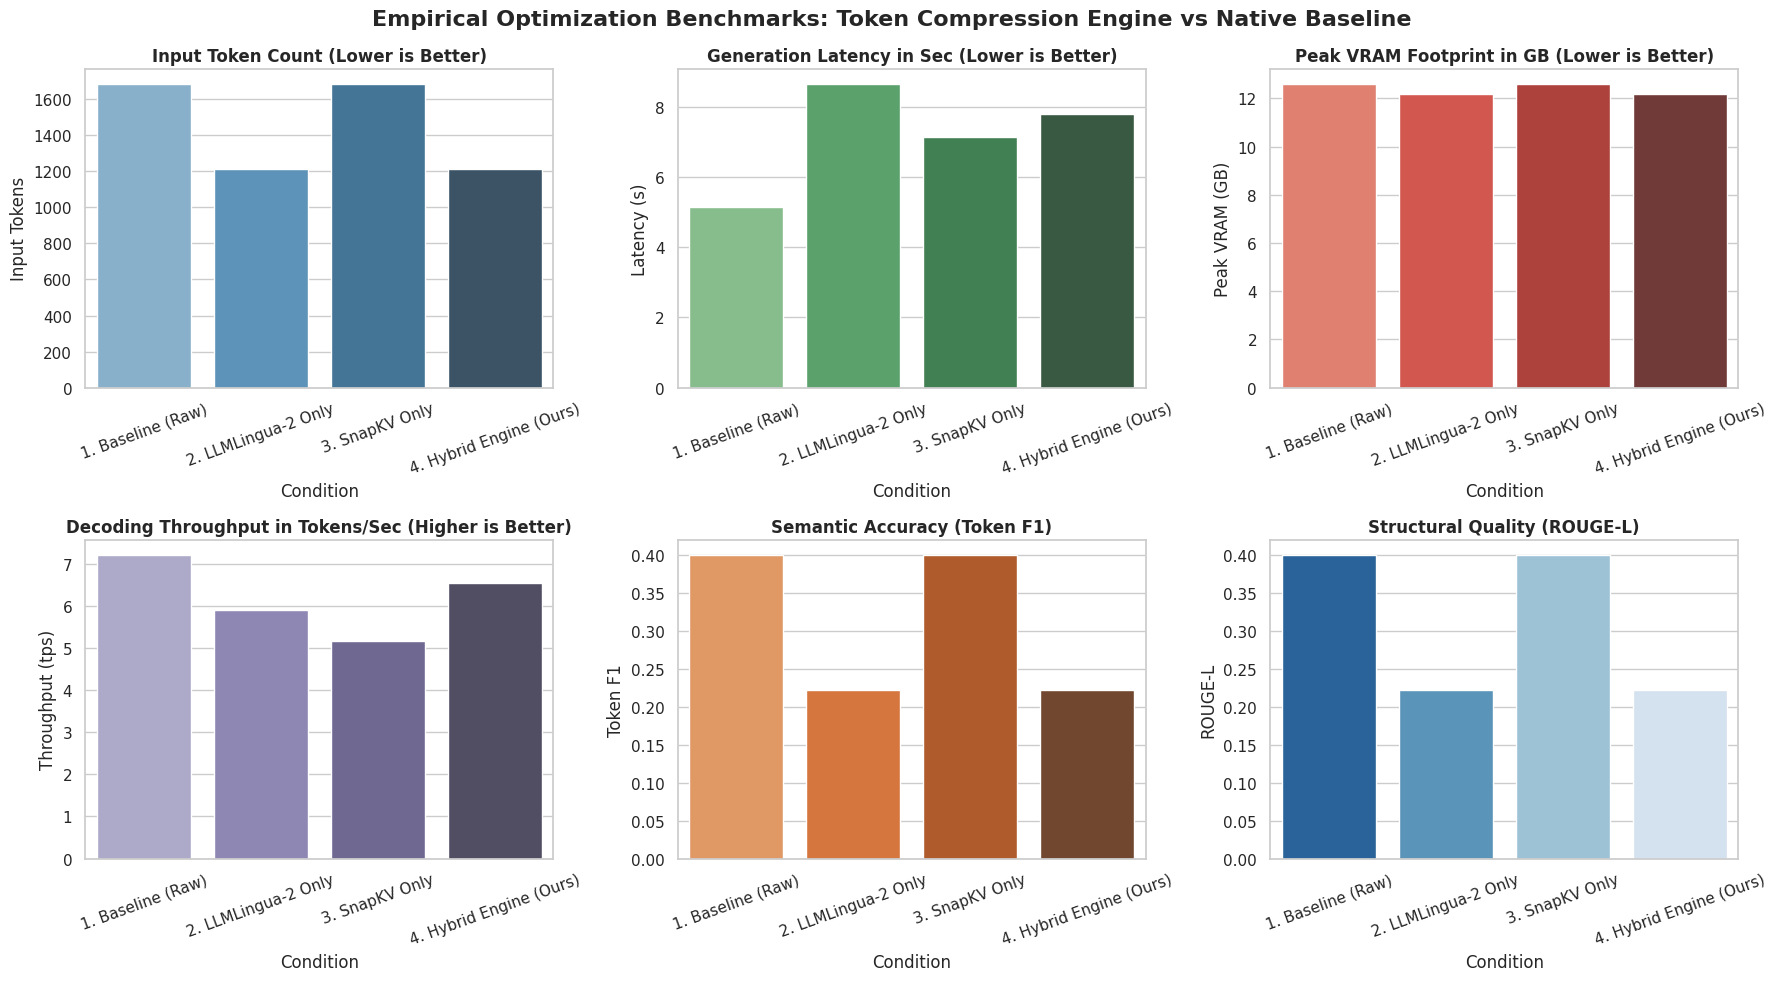

✅ High-Resolution Figure saved as 'capstone_evaluation_dashboard.png'


In [ ]:
# SECTION 6: Publication-Grade Visualizations
sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Empirical Optimization Benchmarks: Token Compression Engine vs Native Baseline", fontsize=16, fontweight="bold", y=0.98)

# 1. Prompt Footprint
sns.barplot(data=df_telemetry, x="Condition", y="Input Tokens", ax=axes[0, 0], palette="Blues_d")
axes[0, 0].set_title("Input Token Count (Lower is Better)", fontweight="bold")
axes[0, 0].tick_params(axis="x", rotation=20)

# 2. End-to-End Latency
sns.barplot(data=df_telemetry, x="Condition", y="Latency (s)", ax=axes[0, 1], palette="Greens_d")
axes[0, 1].set_title("Generation Latency in Sec (Lower is Better)", fontweight="bold")
axes[0, 1].tick_params(axis="x", rotation=20)

# 3. Peak VRAM Footprint
sns.barplot(data=df_telemetry, x="Condition", y="Peak VRAM (GB)", ax=axes[0, 2], palette="Reds_d")
axes[0, 2].set_title("Peak VRAM Footprint in GB (Lower is Better)", fontweight="bold")
axes[0, 2].tick_params(axis="x", rotation=20)

# 4. Generation Throughput
sns.barplot(data=df_telemetry, x="Condition", y="Throughput (tps)", ax=axes[1, 0], palette="Purples_d")
axes[1, 0].set_title("Decoding Throughput in Tokens/Sec (Higher is Better)", fontweight="bold")
axes[1, 0].tick_params(axis="x", rotation=20)

# 5. Token F1 Accuracy
sns.barplot(data=df_telemetry, x="Condition", y="Token F1", ax=axes[1, 1], palette="Oranges_d")
axes[1, 1].set_title("Semantic Accuracy (Token F1)", fontweight="bold")
axes[1, 1].tick_params(axis="x", rotation=20)

# 6. ROUGE-L Alignment
sns.barplot(data=df_telemetry, x="Condition", y="ROUGE-L", ax=axes[1, 2], palette="Blues_r")
axes[1, 2].set_title("Structural Quality (ROUGE-L)", fontweight="bold")
axes[1, 2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.savefig("capstone_evaluation_dashboard.png", dpi=300)
plt.show()
print("✅ High-Resolution Figure saved as 'capstone_evaluation_dashboard.png'")


##SECTION 7: Production Middleware & Interactive Web Interface
Launches a real-time Gradio dashboard with public URL and defines production FastAPI endpoints for enterprise integration.


In [ ]:
# SECTION 7: Interactive Dashboard & FastAPI Endpoints
import gradio as gr

def interactive_inference(raw_text: str, user_query: str, retention_rate: float, enable_kv_eviction: bool, kv_capacity: int):
    if not raw_text.strip() or not user_query.strip():
        return "Please provide both context and a query instruction.", "0", "0", "0%", "0.0s", "0.0 GB"

    try:
        t0 = time.time()
        adaptive_rate = compute_adaptive_retention_rate(raw_text) #Calculates to check whether the code or data to choose the optimal compression rate
        protected_tokens = extract_critical_entities(raw_text) #Scans for error codes, dates, and identifiers by feeding them into force_tokens

        results = compressor.compress_prompt(
            context=[raw_text],
            instruction=user_query,
            rate=adaptive_rate,           # Uses our dynamic entropy-aware rate
            force_tokens=protected_tokens # Uses our zero-loss entity safeguard
        )

        compressed_text = results['compressed_prompt']
        orig_toks = results['origin_tokens']
        comp_toks = results['compressed_tokens']
        savings_pct = round(((orig_toks - comp_toks) / orig_toks) * 100, 1) if orig_toks > 0 else 0.0

        # Stage 1: LLMLingua-2 Prompt Distillation
        req = CompressionRequest(context=raw_text, instruction=user_query, rate=retention_rate)
        c_res = compress_prompt_stage1(req)

        # Format Prompt for Qwen-2.5-7B-Instruct
        prompt = (
            f"<|im_start|>system\nYou are a precise technical assistant.<|im_end|>\n"
            f"<|im_start|>user\nContext:\n{c_res.compressed_text}\n\nQuestion: {user_query}<|im_end|>\n"
            f"<|im_start|>assistant\n"
        )
        inputs = tokenizer(prompt, return_tensors="pt").to("cuda")

        # Stage 2: SnapKV KV-Cache Management
        if enable_kv_eviction:
            snapkv_engine.config.max_capacity = int(kv_capacity)
            snapkv_engine.turn_on()
        else:
            snapkv_engine.turn_off()

        torch.cuda.reset_peak_memory_stats()
        with torch.no_grad():
            outputs = base_model.generate(
                **inputs,
                max_new_tokens=90,
                do_sample=False,
                use_cache=True,
                output_attentions=False  # IMPORTANT: Prevent VRAM allocation spike
            )
        exec_latency = time.time() - t0
        snapkv_engine.turn_off()

        gen_answer = tokenizer.decode(outputs[0][inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()
        peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 3)

        return (
            gen_answer,
            str(c_res.original_tokens),
            str(c_res.compressed_tokens),
            f"{c_res.pruning_percentage}%",
            f"{exec_latency:.2f}s",
            f"{peak_vram:.2f} GB"
        )
    except Exception as e:
        return f"Execution Error: {str(e)}", "0", "0", "0%", "0.0s", "0.0 GB"

with gr.Blocks(theme=gr.themes.Soft(primary_hue="blue")) as demo:
    gr.Markdown("# ⚡ End-to-End Budget-Optimized Token Compression Engine")
    gr.Markdown("### Final Year B.Tech Capstone Project | Deep Learning Infrastructure & Efficient Inference")

    with gr.Row():
        with gr.Column(scale=2):
            text_input = gr.Textbox(
                label="Raw Long Context / Document Payload",
                lines=8,
                placeholder="Paste multi-page document, incident report, or RAG context chunks..."
            )
            query_input = gr.Textbox(
                label="User Query / Extraction Instruction",
                lines=2,
                placeholder="Keep this concise (e.g., 'Write the incident report based on the scenario')."
            )
            with gr.Row():
                retention_slider = gr.Slider(minimum=0.2, maximum=0.8, value=0.5, step=0.1, label="Retention Rate (Stage 1)")
                kv_toggle = gr.Checkbox(label="Enable SnapKV Eviction (Stage 2)", value=True)
                budget_slider = gr.Slider(minimum=128, maximum=1024, value=512, step=64, label="KV Cache Budget (Tokens)")
            submit_btn = gr.Button("Compress & Infer", variant="primary")

        with gr.Column(scale=2):
            response_box = gr.Textbox(label="Generated Response from Compressed Engine", lines=6)
            with gr.Row():
                orig_label = gr.Textbox(label="Original Tokens")
                comp_label = gr.Textbox(label="Compressed Tokens")
                save_label = gr.Textbox(label="Token Savings")
            with gr.Row():
                lat_label = gr.Textbox(label="Total Latency")
                vram_label = gr.Textbox(label="Peak VRAM Footprint")

    submit_btn.click(
        fn=interactive_inference,
        inputs=[text_input, query_input, retention_slider, kv_toggle, budget_slider],
        outputs=[response_box, orig_label, comp_label, save_label, lat_label, vram_label]
    )

print("Starting Gradio Web Application...")
demo.launch(share=True, debug=False)

/tmp/ipykernel_865/566945583.py:70: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(primary_hue="blue")) as demo:


Starting Gradio Web Application...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://56aeec7090c3290a30.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


##SECTION 8: GitHub Version Control Integration
Automatically commits the completed capstone code, empirical metrics, and figures to your GitHub repository.


In [ ]:
# SECTION 8: Git Integration
from google.colab import userdata
import os

REPO_URL = "github.com/ShikharVeer10/TokenCompression.git"
USER_NAME = "ShikharVeer10"
USER_EMAIL = "shikharveer01@gmail.com"

try:
    token = userdata.get('GITHUB_TOKEN')
    remote = f"https://{USER_NAME}:{token}@{REPO_URL}"

    !git config --global user.email "{USER_EMAIL}"
    !git config --global user.name "{USER_NAME}"

    if not os.path.exists('.git'):
        !git init
        !git remote add origin {remote}

    !git add .
    !git commit -m "Complete Capstone Project: End-to-End Dual-Stage Token Compression with 6-Metric Telemetry"
    !git branch -M main
    !git push -u origin main --force
    print("✅ Successfully synchronized with GitHub repository!")
except Exception as e:
    print(f"Notice: {e}. If pushing to GitHub, add 'GITHUB_TOKEN' to Colab Secrets (Key icon on left sidebar).")


SECTION - 9 ENTITY SAFEGUARD AND ADAPTIVE PRUNING

In [ ]:
import re

To prevent the compressor from accidentally deleting critical numbers, dates or any technical identifiers


In [ ]:
def extract_critical_entities(text:str) -> list[str]:

  patterns=[
      r'\b0x[0-9A-Fa-f]+\b',                 # Hex error codes (e.g., 0xEE42)
      r'\b[A-Z0-9]{4,}-[A-Z0-9-]+\b',       # Alphanumeric hashes/UUIDs (e.g., HASH-ALPHA-9942)
      r'\b\d{1,2}:\d{2}\s?(?:UTC|AM|PM)?\b',    # Timestamps
      r'\$[\d,]+(?:\.\d{2})?\b',             # Financial amounts
      r'\bnode-\w+\b'                        # Node identifiers (e.g., node-9B)
  ]

  extracted=set()
  for pattern in patterns:
    matches=re.findall(pattern,text)
    for m in matches:
      extracted.add(m)

  #For structural punctuation
  standard_protected = ['\n', '?', '.', ':', '-', '"', "'",'[',']']
  return list(extracted) + standard_protected

print("Zero loss entity safeguard loaded successfully")


Zero loss entity safeguard loaded successfully


In [ ]:
def compute_adaptive_retention_rate(context:str) -> float:
  words=context.split()
  if not words:
    return 0.5

  unique_ratio=len(set(words)) / len(words)

  tech_markers=len(re.findall(r'[\{\}\[\]\(\)=<>0-9_]|\b[A-Z]{3,}\b', context))
  density_score=tech_markers/len(words)

  if density_score>0.15 or unique_ratio>0.65:
    return 0.70
  elif unique_ratio<0.40:
    return 0.35
  else:
    return 0.50

print("Dynamic Entropy-Aware Allocator loaded")


Dynamic Entropy-Aware Allocator loaded


Test-cell for entropy allocation

In [ ]:
sample_context = "System error 0xEE42 triggered on node-9B at 04:12 UTC."
sample_query = "What error code occurred?"
adaptive_rate = compute_adaptive_retention_rate(sample_context)
protected_tokens = extract_critical_entities(sample_context)

print(f"Dynamic Retention Rate Selected: {adaptive_rate}")
print(f"Protected Entities Safeguarded: {protected_tokens}")

Dynamic Retention Rate Selected: 0.7
Protected Entities Safeguarded: ['node-9B', '04:12 UTC', '0xEE42', '\n', '?', '.', ':', '-', '"', "'", '[', ']']
